[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/05_substructure_smarts.ipynb)

# 05 · Substructure Search and SMARTS

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~45 min*

Similarity asks *how alike* two molecules are; substructure search asks *does this molecule
contain that fragment?* It is how chemists find chemotypes, warheads, and reactive or
assay-interfering groups.

**Learning objectives.** By the end of this notebook you will be able to:

- search molecules for a substructure and highlight the match
- write SMARTS patterns for common functional groups
- count chemotypes and compare their activity in a real dataset
- flag problematic compounds with the PAINS filter catalog

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
RDLogger.DisableLog("rdApp.*")

egfr = pd.read_csv(f"{DATA_DIR}/egfr_chembl37_ic50.csv")
egfr["mol"] = egfr["smiles"].apply(Chem.MolFromSmiles)
esol = pd.read_csv(f"{DATA_DIR}/esol_delaney.csv")
esol["mol"] = esol["smiles"].apply(Chem.MolFromSmiles)
gefitinib = egfr.loc[egfr.compound_id == "CHEMBL939", "mol"].iloc[0]

## 1. Substructure match with a SMILES query

gefitinib contains quinazoline: True
matching atom indices: (20, 2, 3, 4, 5, 6, 7, 8, 18, 19)


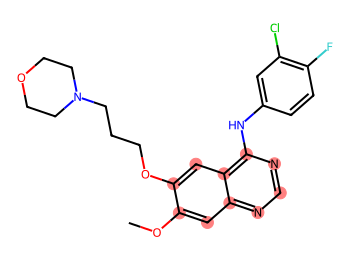

In [3]:
quinazoline = Chem.MolFromSmiles("c1ccc2ncncc2c1")
print("gefitinib contains quinazoline:", gefitinib.HasSubstructMatch(quinazoline))
match = gefitinib.GetSubstructMatch(quinazoline)
print("matching atom indices:", match)
Draw.MolToImage(gefitinib, size=(350, 260), highlightAtoms=match)

## 2. SMARTS: a query language for substructures

SMILES describes *a molecule*; **SMARTS** describes *a pattern* and can say things like
"any halogen" or "a nitrogen with exactly one hydrogen".

| SMARTS | Meaning |
|---|---|
| `[F,Cl,Br,I]` | any halogen |
| `[CX3](=O)[OX2H1]` | carboxylic acid |
| `[NX3;H2][#6]` | primary amine on carbon |
| `c1ccccc1` / `a` | benzene ring / any aromatic atom |
| `[#7]` | any nitrogen (aromatic or not) |
| `[R]` / `[!R]` | ring atom / non-ring atom |
| `*` | any atom |

In [4]:
patterns = {
    "carboxylic acid": "[CX3](=O)[OX2H1]",
    "primary amine": "[NX3;H2][#6]",
    "halogen": "[F,Cl,Br,I]",
    "phenol": "c[OX2H1]",
    "ester": "[#6][CX3](=O)[OX2][#6]",
}
queries = {name: Chem.MolFromSmarts(s) for name, s in patterns.items()}
counts = {name: int(esol["mol"].apply(lambda m: m.HasSubstructMatch(q)).sum()) for name, q in queries.items()}
pd.Series(counts, name="ESOL compounds containing the group")

carboxylic acid      0
primary amine       59
halogen            332
phenol              91
ester               98
Name: ESOL compounds containing the group, dtype: int64

Notice the **zero** for carboxylic acids: the ESOL set contains no free carboxylic acids at all.
Simple substructure counts are a quick way to discover what a dataset does *not* cover, and therefore where a
model trained on it should not be trusted. Let's look at the esters instead.

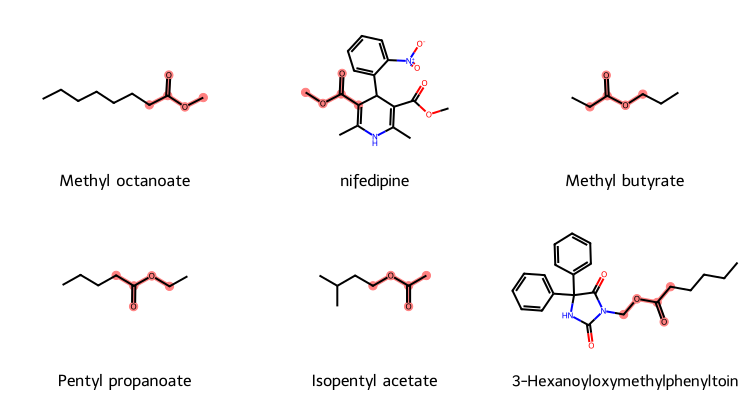

In [5]:
esters = esol[esol["mol"].apply(lambda m: m.HasSubstructMatch(queries["ester"]))].head(6)
Draw.MolsToGridImage(list(esters["mol"]), molsPerRow=3, subImgSize=(250, 200),
                     legends=list(esters["compound_id"]),
                     highlightAtomLists=[m.GetSubstructMatch(queries["ester"]) for m in esters["mol"]])

## 3. Counting matches

`GetSubstructMatches` returns *every* occurrence. Here: the number of aromatic rings matched by a benzene pattern.

In [6]:
benzene = Chem.MolFromSmarts("c1ccccc1")
esol["n_benzene"] = esol["mol"].apply(lambda m: len(m.GetSubstructMatches(benzene)))
esol.groupby("n_benzene")["logS"].agg(["size", "median"]).round(2)

,size,median
n_benzene,,
0,563,-2.06
1,358,-2.82
2,168,-4.62
3,18,-6.18
4,15,-7.02
5,4,-8.28
6,1,-9.02
7,1,-9.33


## 4. Chemotypes and activity in the EGFR set

The **4-anilinoquinazoline** scaffold is the classic EGFR chemotype (gefitinib, erlotinib, lapatinib).
How common is it in the dataset, and are those compounds more potent?

In [7]:
anilinoquinazoline = Chem.MolFromSmarts("c1ccccc1[NX3;H1]c1ncnc2ccccc12")
egfr["anilinoquinazoline"] = egfr["mol"].apply(lambda m: m.HasSubstructMatch(anilinoquinazoline))
egfr.groupby("anilinoquinazoline")["p_activity"].agg(["size", "median", "mean"]).round(2)

,size,median,mean
anilinoquinazoline,,,
False,5151,6.85,6.87
True,1720,7.50,7.42


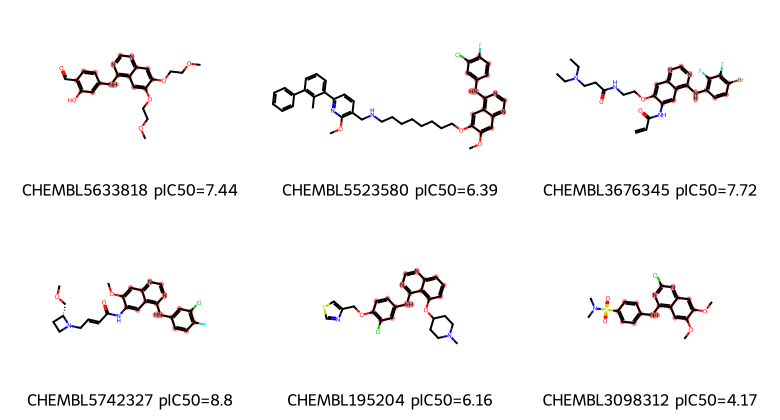

In [8]:
sample = egfr[egfr.anilinoquinazoline].sample(6, random_state=1)
Draw.MolsToGridImage(list(sample["mol"]), molsPerRow=3, subImgSize=(260, 210),
                     legends=[f"{c} pIC50={p}" for c, p in zip(sample.compound_id, sample.p_activity)],
                     highlightAtomLists=[m.GetSubstructMatch(anilinoquinazoline) for m in sample["mol"]])

A difference in medians is an observation about *this* dataset, not proof that the scaffold causes
potency: medicinal chemists made many more optimized analogues of successful chemotypes.

## 5. PAINS: pan-assay interference compounds

PAINS (Baell & Holloway, *J. Med. Chem.* 2010) are substructures that frequently produce false
positives in screening assays. RDKit ships them as a filter catalog.

In [9]:
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
pains = FilterCatalog(params)

def first_pains(m):
    entry = pains.GetFirstMatch(m)
    return entry.GetDescription() if entry is not None else None

egfr["pains"] = egfr["mol"].apply(first_pains)
print(f"{egfr['pains'].notna().sum()} of {len(egfr)} EGFR compounds match a PAINS pattern")
egfr["pains"].value_counts().head(8)

491 of 6871 EGFR compounds match a PAINS pattern


pains
anil_di_alk_A(478)    201
mannich_A(296)         59
catechol_A(92)         48
quinone_A(370)         36
ene_one_ene_A(57)      33
indol_3yl_alk(461)     25
azo_A(324)             15
ene_five_het_B(90)     13
Name: count, dtype: int64

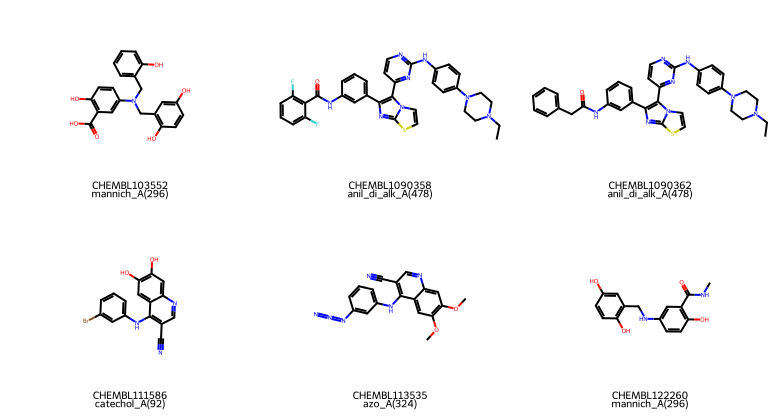

In [10]:
flagged = egfr[egfr["pains"].notna()].head(6)
Draw.MolsToGridImage(list(flagged["mol"]), molsPerRow=3, subImgSize=(260, 210),
                     legends=[f"{c}\n{p}" for c, p in zip(flagged.compound_id, flagged.pains)])

A PAINS match is a **warning to look closer**, not an automatic rejection. Some approved drugs contain PAINS motifs.

### ✏️ Exercise 1

Count the ESOL compounds that contain at least one halogen atom, and compare their median logS with the halogen-free compounds.

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
has_hal = esol["mol"].apply(lambda m: m.HasSubstructMatch(Chem.MolFromSmarts("[F,Cl,Br,I]")))
print(has_hal.sum(), "compounds with a halogen")
print(esol.groupby(has_hal)["logS"].median().rename({True: "halogen", False: "no halogen"}))
```

</details>

### ✏️ Exercise 2

Covalent EGFR inhibitors (e.g. afatinib, osimertinib) carry an **acrylamide** warhead. Using the SMARTS `[CH2]=[CH]C(=O)[NX3]`, count the EGFR compounds that contain it and report their median pIC50.

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
acrylamide = Chem.MolFromSmarts("[CH2]=[CH]C(=O)[NX3]")
has_acr = egfr["mol"].apply(lambda m: m.HasSubstructMatch(acrylamide))
print(has_acr.sum(), "compounds with a terminal acrylamide")
print("median pIC50:", egfr.loc[has_acr, "p_activity"].median(), "vs others:", egfr.loc[~has_acr, "p_activity"].median())
```

</details>

### ✏️ Exercise 3

Write a SMARTS that matches a nitro group in **both** of its common representations (`[N+](=O)[O-]` and the pentavalent `N(=O)=O`) and test it on `c1ccccc1[N+](=O)[O-]` and `c1ccccc1N(=O)=O`.

*Hint:* recursive SMARTS `$(...)` lets you combine whole patterns with a comma (OR).

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
nitro = Chem.MolFromSmarts("[$([NX3+](=O)[O-]),$([NX3](=O)=O)]")
for s in ["c1ccccc1[N+](=O)[O-]", "c1ccccc1N(=O)=O", "c1ccccc1N"]:
    print(f"{s:<22}", Chem.MolFromSmiles(s).HasSubstructMatch(nitro))
```

</details>

## Key takeaways

- `HasSubstructMatch` / `GetSubstructMatches` answer "does it contain…?" and "how many times?".
- SMARTS expresses chemical patterns; test every new pattern on positive **and** negative examples.
- Filter catalogs (PAINS, Brenk, …) flag compounds that deserve a second look.

**Next:** [06 · Structure standardization and curation](06_standardization_curation.ipynb).